# What can be represented on a map?

Several types of geographic data :  <br>
• Point <br>
• LineString <br>
• Polygon <br>
• others : LinearRing, MultiPolygon… <br>

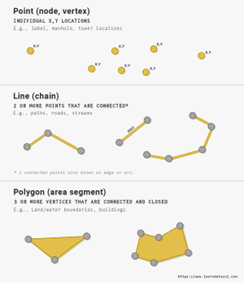 <br>

Several types of maps : <br>
• Points representation <br>
• Choropleth maps <br>

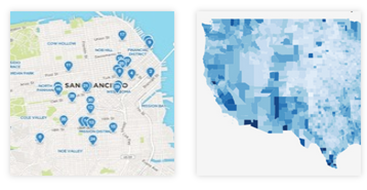

💡Read this article for more information : https://www.learndatasci.com/tutorials/geospatial-data-python-geopandas-shapely/

# Several libraries to analyse geographic data

• Shapely : manipulate and analyse geometric objects <br>
Documentation : https://shapely.readthedocs.io/en/stable/manual.html

• Geopandas : process (read...) geographic data <br>
Documentation : https://geopandas.org/en/v0.4.0/index.html

• Pyproj : manage geographic coordinate system <br>
Documentation : https://pyproj4.github.io/pyproj/stable/index.html

### Installing GeoPandas

To avoid common problems with geopandas installation, create a virtual environment. <br>

Follow : https://medium.com/analytics-vidhya/fastest-way-to-install-geopandas-in-jupyter-notebook-on-windows-8f734e11fa2b <br>
until opening Jupyter. <br>

Reinstall packages not included like plotly.

In [7]:
# Import libraries

import pandas as pd
import numpy as np

import matplotlib
import plotly.express as px

import shapely
from shapely.geometry import Point, LineString, Polygon, MultiPolygon

import geopandas as gpd

# Reading data

Different types of files can contain geographic data : geojson, shapefiles (.shp),... but also CSV or Excel.

In [9]:
#Read French areas data (regions-20140306-100m.shp) with geopandas.read_file
regions = gpd.read_file("../Régions-20140306-100m-shp-20260804/regions-20140306-100m.shp")

In [10]:
regions.head()

,code_insee,nom,nom_cl,insee_cl,nuts2,iso3166_2,wikipedia,nb_dep,nb_comm,surf_km2,geometry
0,42,Alsace,Strasbourg,67482,FR42,None,fr:Alsace,2,904,8328.0,"POLYGON ((7.43003 47.45949, 7.4288 47.45388, 7..."
1,72,Aquitaine,Bordeaux,33063,FR61,None,fr:Aquitaine,5,2296,41818.0,"MULTIPOLYGON (((-1.75633 43.38372, -1.7559 43...."
2,83,Auvergne,Clermont-Ferrand,63113,FR72,None,fr:Auvergne,4,1310,26172.0,"POLYGON ((3.3369 44.95609, 3.31531 44.94425, 3..."
3,25,Basse-Normandie,Caen,14118,FR25,None,fr:Basse-Normandie,3,1812,17786.0,"MULTIPOLYGON (((-1.51504 48.66027, -1.51304 48..."
4,26,Bourgogne,Dijon,21231,FR26,None,fr:Bourgogne,4,2046,31752.0,"POLYGON ((4.76293 46.17583, 4.75864 46.17205, ..."


In [11]:
type(regions)

geopandas.geodataframe.GeoDataFrame

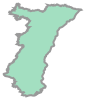

In [12]:
regions.geometry.iloc[0]

In [13]:
#Read energy production data (installations-production-elec-gaz.csv)
df_energy_prod = pd.read_csv("../installations-production-elec-gaz.csv",sep=";")

In [14]:
df_energy_prod.head()

,1_f_commune_pdl,count,date_des_donnees,code_epci,s_3_prod_i_regime_d_exploitation,s_3_prod_d_filiere,coordonnees,1_f_code_insee_pdl
0,Mazan,1,2020-03,248400053,NaN,Éolien,"44.0545320098, 5.13048600927",84072
1,Mazangé,14,2020-03,200072072,Realised,Solaire,"47.8402255423, 0.948834044312",41131
2,Mazaugues,26,2020-03,200068104,Realised,Solaire,"43.3448761166, 5.89589582308",83076
3,Mazerat-Aurouze,1,2020-03,200073393,Realised,Hydraulique,"45.1875462661, 3.5663385327",43131
4,Mazeray,4,2020-03,200041689,NaN,Solaire,"45.9158199464, -0.559708232455",17226


In [15]:
type(df_energy_prod)

pandas.core.frame.DataFrame

<br>
When we import data with geopandas, Python reads them like geographic data, but for CSV, coordinates are strings. We have to convert the column "coordonnees" to get a geometric object.

In [16]:
# Create a column "geometry" that looks like : 'POINT (latitude longitude)'
def coord_to_point(coord):
    if pd.isna(coord):
        return None
    lat,lon = map(float, coord.split(','))
    return Point(lon,lat)

df_energy_prod['geometry'] = df_energy_prod['coordonnees'].apply(coord_to_point)

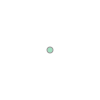

In [17]:
df_energy_prod['geometry'].iloc[0]

In [18]:
type(df_energy_prod)

pandas.core.frame.DataFrame

In [19]:
# Convert df_energy_prod to GeoDataFrame
df_energy_prod = gpd.GeoDataFrame(df_energy_prod)

In [20]:
type(df_energy_prod)

geopandas.geodataframe.GeoDataFrame

# Visualising data statically

With .plot(), we can view maps statically :

<Axes: >

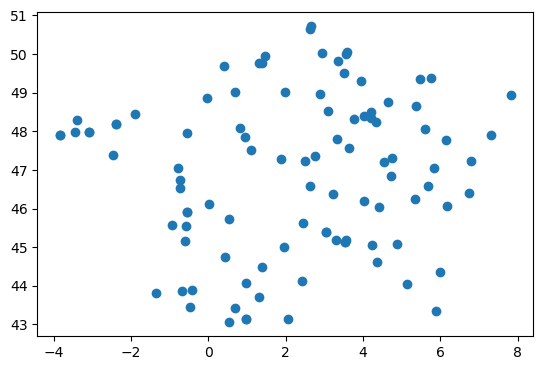

In [21]:
# Visualise df_energy_prod 
df_energy_prod.iloc[0:100].plot()

<Axes: >

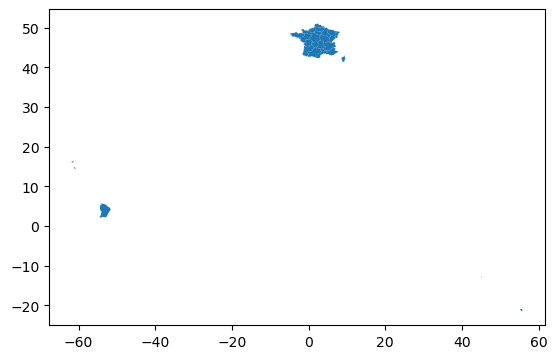

In [22]:
#Visualise regions
regions.plot()

# Visualising maps interactively

We'll use Plotly Express functions, one for points and one for polygons

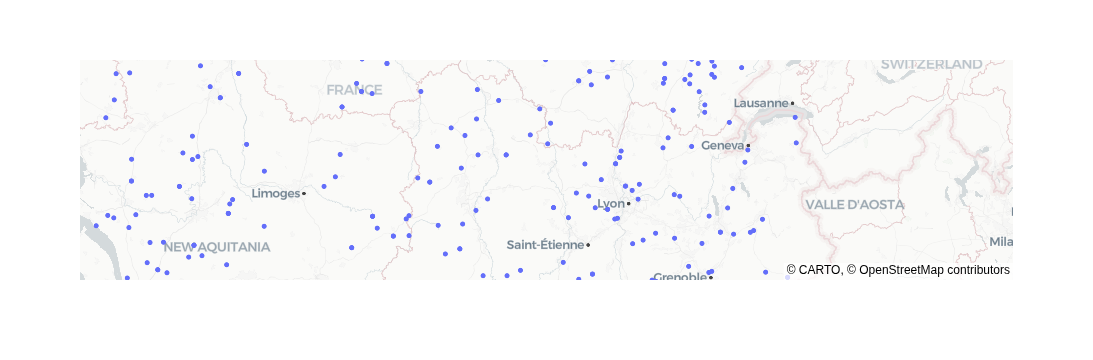

In [23]:
# First 1000 points
fig = px.scatter_map(df_energy_prod.iloc[0:1000],
                        lat=df_energy_prod['geometry'].iloc[0:1000].y, lon=df_energy_prod['geometry'].iloc[0:1000].x, 
                        map_style="carto-positron", #fond de carte
                        zoom=6, center = {"lat": 46, "lon": 4}) #positionnement par défaut de la carte
                        
fig.show()

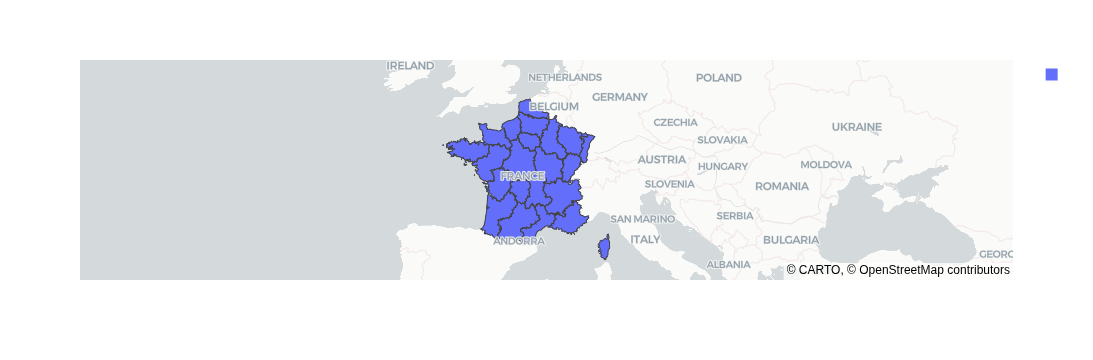

In [24]:
fig = px.choropleth_map(regions, geojson = regions["geometry"],
                          locations = regions.index,
                          map_style="carto-positron",
                          zoom=3, center = {"lat": 47, "lon": 4})
fig.show()

💡 Several libraries can be used to create maps : <br>
Interactive: Plotly, Folium, Mplleaflet… <br>
Static: Basemap, Cartopy… <br>

You can compare on : https://github.com/ispmarin/maps and with the libraries documentation.

# Bonus

With Plotly documentation (https://plotly.com/python/maps/), improve the maps : 
- color the points according to the energy source
- change mapbox style
- customise the hovertemplate
- ...